# Chennai Tmax: EDA and Extreme Value Analysis (Person B, Part 1)
Source: OpenCity daily temperature, 1951 to 2024-06-22. **Caveat:** IMD gridded data up to 2020, Nungambakkam station from 2021, so there is a splice at 2021 that can bias trend results.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from src import evt_analysis as evt
plt.rcParams.update({'figure.dpi':100,'axes.grid':True,'grid.alpha':.3})
s_all = evt.load_processed_tmax('../data/processed/chennai_daily.csv')   # Person A's output
HOM_END = 2020   # config: analysis.homogeneous_end_year (grid-based IMD years, no station splice)
s = evt.restrict_years(s_all, end=HOM_END)
print('full record', s_all.index.min().date(), '-', s_all.index.max().date(), '| primary EVT period', s.index.min().date(), '-', s.index.max().date(), len(s), 'rows;', s.isna().sum(), 'missing Tmax in primary period')

full record 1951-01-01 - 2024-06-22 | primary EVT period 1951-01-01 - 2020-12-31 25568 rows; 1 missing Tmax in primary period


## 1. Data quality

In [2]:
raw = pd.read_csv('../data/processed/chennai_daily.csv')
print('Missing by year (top):'); print(s.isna().groupby(s.index.year).sum().loc[lambda x:x>0])
print('Rain column is empty before 2021 (', raw['rain'].isna().sum(), 'of', len(raw), 'rows): do not use rain as a feature for the full history.')
print(s.describe().round(2))

Missing by year (top):
date
2019    1
Name: tmax, dtype: int64
Rain column is empty before 2021 ( 25652 of 26837 rows): do not use rain as a feature for the full history.
count    25567.00
mean        33.70
std          3.38
min         23.55
25%         30.87
50%         33.88
75%         36.20
max         44.96
Name: tmax, dtype: float64


## 2. Seasonality and long-term change

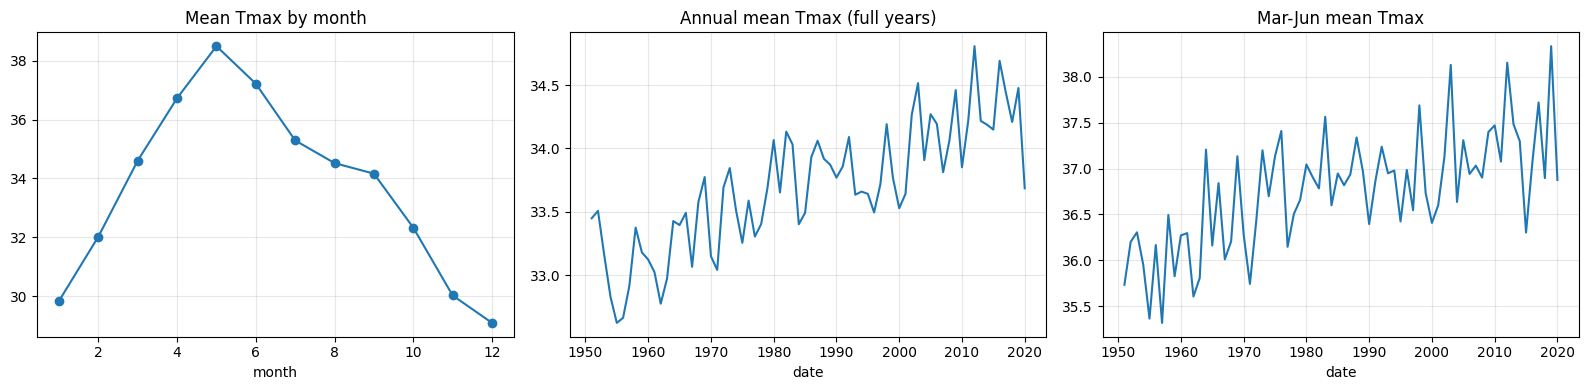

In [3]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
s.groupby(s.index.month).mean().plot(ax=ax[0],marker='o'); ax[0].set_title('Mean Tmax by month'); ax[0].set_xlabel('month')
ann=s.groupby(s.index.year).mean(); ann[s.groupby(s.index.year).count()>300].plot(ax=ax[1]); ax[1].set_title('Annual mean Tmax (full years)')
smr=evt.summer_only(s); smr.groupby(smr.index.year).mean().plot(ax=ax[2]); ax[2].set_title('Mar-Jun mean Tmax')
plt.tight_layout(); plt.show()

## 3. Hot-day frequency (model-free)

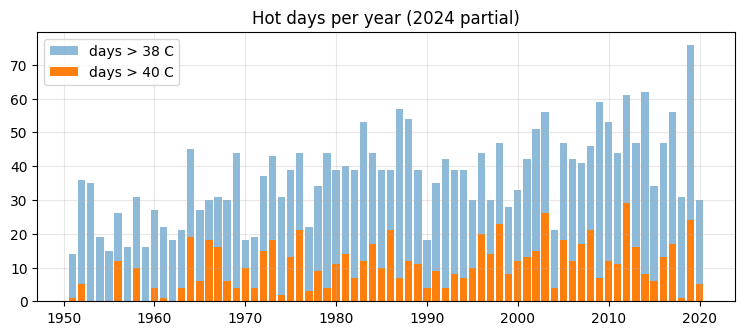

date
1950     3.1
1960     7.8
1970     9.9
1980    12.2
1990    10.7
2000    14.5
2010    13.7
2020     5.0
Name: mean days>40C per year, dtype: float64


In [4]:
d40=evt.empirical_exceedance_by_year(s,40); d38=evt.empirical_exceedance_by_year(s,38)
fig,ax=plt.subplots(figsize=(9,3.5)); ax.bar(d38.index,d38.values,label='days > 38 C',alpha=.5); ax.bar(d40.index,d40.values,label='days > 40 C'); ax.legend(); ax.set_title('Hot days per year (2024 partial)'); plt.show()
print(d40.groupby(lambda y:y//10*10).mean().round(1).rename('mean days>40C per year'))

## 4. Block maxima and GEV\nAnnual maximum of Mar-Jun Tmax. Years with fewer than 60 summer observations are dropped.

n=70  xi=-0.230  loc=41.20  scale=1.14  KS p=0.39
xi < 0 means a bounded upper tail: plausible for Tmax, but with 74 points xi is uncertain.


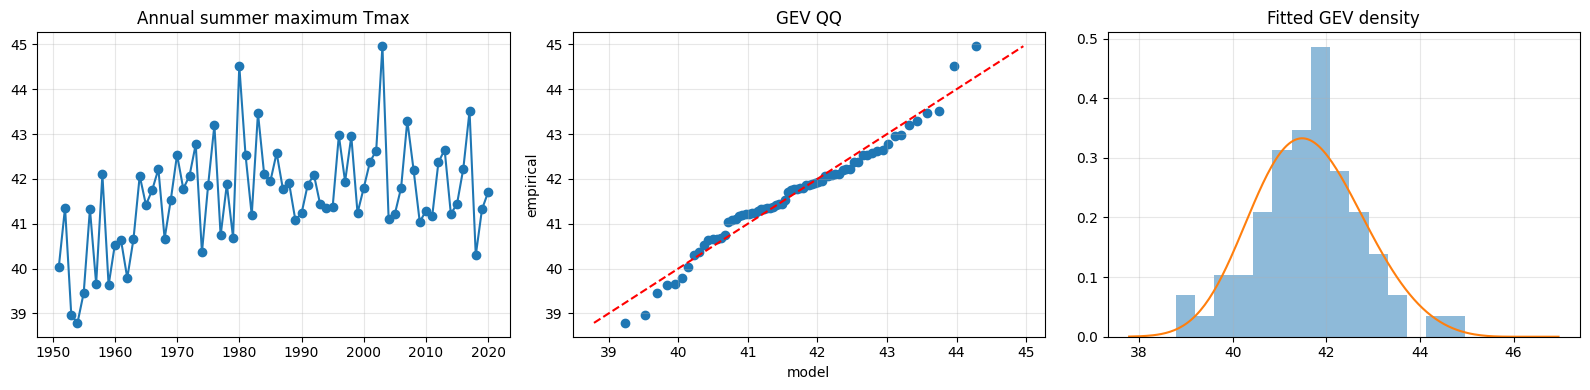

In [5]:
bm=evt.block_maxima(s); gev=evt.fit_gev(bm)
print(f'n={gev.n}  xi={gev.xi:.3f}  loc={gev.loc:.2f}  scale={gev.scale:.2f}  KS p={evt.gev_ks_pvalue(bm,gev):.2f}')
print('xi < 0 means a bounded upper tail: plausible for Tmax, but with 74 points xi is uncertain.')
fig,ax=plt.subplots(1,3,figsize=(16,4))
ax[0].plot(bm.index,bm.values,'o-'); ax[0].set_title('Annual summer maximum Tmax')
q=evt.gev_qq(bm,gev); ax[1].scatter(q.model,q.empirical); lim=[q.min().min(),q.max().max()]; ax[1].plot(lim,lim,'r--'); ax[1].set_title('GEV QQ'); ax[1].set_xlabel('model'); ax[1].set_ylabel('empirical')
ax[2].hist(bm,bins=15,density=True,alpha=.5); xs=np.linspace(bm.min()-1,bm.max()+2,200); ax[2].plot(xs,stats.genextreme.pdf(xs,-gev.xi,gev.loc,gev.scale)); ax[2].set_title('Fitted GEV density')
plt.tight_layout(); plt.show()

## 5. Return levels with 95% CIs

,T,estimate,lo95,hi95
0,2.0,41.60,41.32,41.93
1,5.0,42.64,42.24,42.95
2,10.0,43.20,42.74,43.52
3,25.0,43.77,43.15,44.24
4,50.0,44.13,43.38,44.71
5,100.0,44.43,43.54,45.18


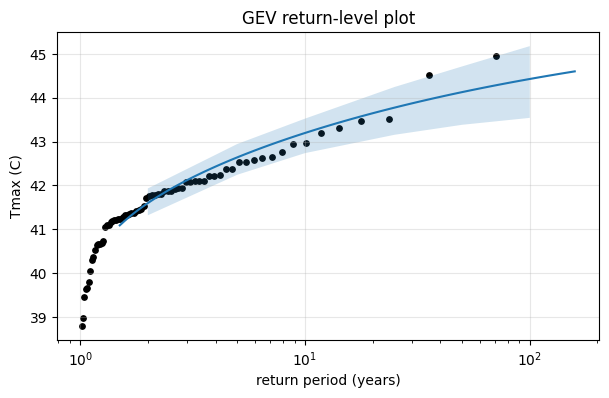

P(annual summer max > 42 C): 0.371  > 44 C: 0.0261


In [6]:
rl=evt.bootstrap_gev_return_levels(bm,T=[2,5,10,25,50,100],n_boot=500); display(rl.round(2))
T=np.logspace(np.log10(1.5),2.2,100); n=len(bm); emp_T=(n+1)/np.arange(1,n+1); emp=np.sort(bm.values)[::-1]
fig,ax=plt.subplots(figsize=(7,4)); ax.semilogx(T,gev.return_level(T)); ax.scatter(emp_T,emp,s=15,c='k'); ax.fill_between(rl['T'],rl.lo95,rl.hi95,alpha=.2)
ax.set_xlabel('return period (years)'); ax.set_ylabel('Tmax (C)'); ax.set_title('GEV return-level plot'); plt.show()
print('P(annual summer max > 42 C):', round(evt.gev_exceedance_prob(gev,42),3), ' > 44 C:', round(evt.gev_exceedance_prob(gev,44),4))

## 6. Stationarity check\nA trend or the 2021 splice would violate the stationary-GEV assumption.

In [7]:
print('Kendall/Theil-Sen:', evt.trend_test(bm)); display(evt.compare_periods(bm,1991).round(2))
tf=evt.fit_gev_trend(bm); print(f'Trend-in-location GEV: {tf.slope_per_decade:.2f} C/decade, LRT vs stationary p = {tf.p_value:.5f}')
print('10-yr level, trend model:', round(float(evt.trend_return_level(tf, int(bm.index.min()), 10)),2), 'C in', int(bm.index.min()), 'vs', round(float(evt.trend_return_level(tf, int(bm.index.max()), 10)),2), 'C in', int(bm.index.max()))
bm_full = evt.block_maxima(s_all); print('Sensitivity, full record to', int(bm_full.index.max()), ':', evt.trend_test(bm_full), 'LRT p =', round(evt.fit_gev_trend(bm_full).p_value,5))
print('Annual maxima 2019-2024 (2021+ is station data):', bm_full.loc[2019:].round(1).to_dict())

Kendall/Theil-Sen: {'tau': 0.24336668907234907, 'p_value': 0.0029192167054560396, 'slope_per_decade': 0.1999480903846149}


,period,n,xi,loc,scale,RL10,RL50
0,early,40,-0.25,40.93,1.21,43.01,43.93
1,late,30,-0.01,41.56,0.72,43.16,44.30


Trend-in-location GEV: 0.25 C/decade, LRT vs stationary p = 0.00005
10-yr level, trend model: 42.17 C in 1951 vs 43.87 C in 2020


Sensitivity, full record to 2024 : {'tau': 0.18717580140512158, 'p_value': 0.018430404830576206, 'slope_per_decade': 0.14516030645161265} LRT p = 0.00066
Annual maxima 2019-2024 (2021+ is station data): {2019: 41.3, 2020: 41.7, 2021: 41.2, 2022: 40.1, 2023: 42.3, 2024: 41.1}


## 7. Peaks over threshold (cross-check)

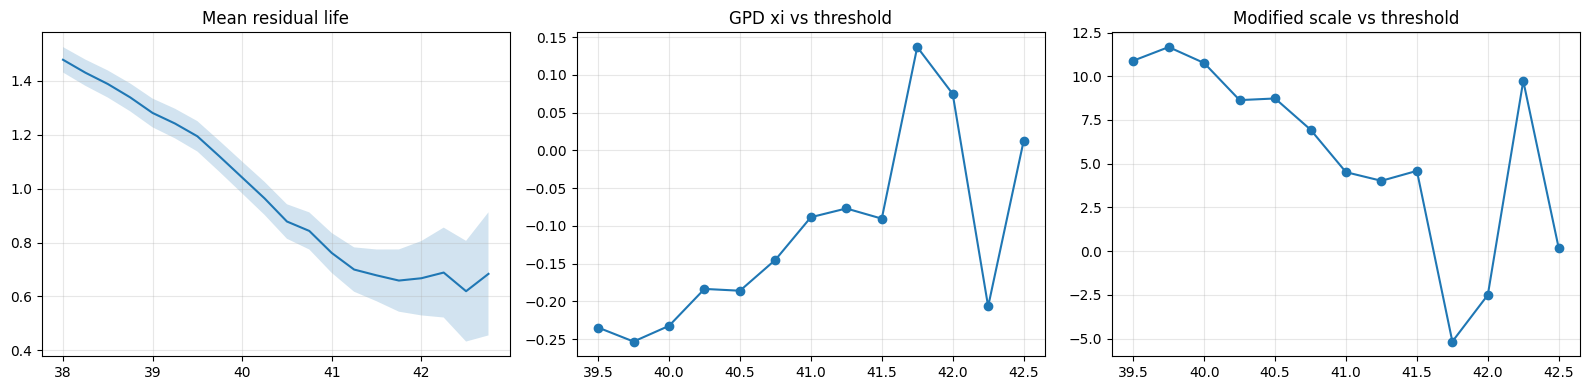

In [8]:
summ=evt.summer_only(s).dropna(); us=np.arange(38,43,.25)
mrl=evt.mean_residual_life(summ,us); ts=evt.threshold_stability(s,np.arange(39.5,42.6,.25))
fig,ax=plt.subplots(1,3,figsize=(16,4))
ax[0].plot(mrl.u,mrl.mean_excess); ax[0].fill_between(mrl.u,mrl.lo,mrl.hi,alpha=.2); ax[0].set_title('Mean residual life')
ax[1].plot(ts.u,ts.xi,'o-'); ax[1].set_title('GPD xi vs threshold'); ax[2].plot(ts.u,ts.mod_scale,'o-'); ax[2].set_title('Modified scale vs threshold')
plt.tight_layout(); plt.show()

In [9]:
u=float(np.percentile(summ,97)); gpd=evt.fit_gpd(s,u)
print(f'threshold={u:.2f} C (97th pct of summer days)  cluster peaks={gpd.n_peaks}  xi={gpd.xi:.3f}  sigma={gpd.sigma:.2f}')
cmp=pd.DataFrame({'T':[10,25,50,100],'GEV':gev.return_level([10,25,50,100]),'GPD':gpd.return_level([10,25,50,100])}); display(cmp.round(2))

threshold=41.23 C (97th pct of summer days)  cluster peaks=73  xi=-0.048  sigma=0.80


,T,GEV,GPD
0,10,43.20,43.00
1,25,43.77,43.64
2,50,44.13,44.10
3,100,44.43,44.55


## 8. Findings to hand over\n- Primary fit (1951-2020, grid years only): 10-year level about 43.2 C, 20-year about 43.7 C, 50-year about 44.1 C. GEV and GPD agree. The 100-year value is an extrapolation.\n- **Stationarity is not supported.** Annual maxima rise by about 0.2 C per decade and a GEV with a trending location beats the stationary one (likelihood-ratio p < 0.001, also on the full record). Stationary return levels therefore understate present-day extremes: under the trend model the 10-year level moves from about 42.2 C (1951) to about 43.9 C (2020).\n- The two largest annual maxima (44.96 C in 2003, 44.52 C in 1980) lie above the stationary 95% band, another sign the bounded-tail stationary fit is optimistic at the top.\n- Days above 40 C per year are lower in the 2020s sample; this coincides with the grid-to-station splice in 2021 and should not be read as cooling.\n- For ML and labels: IMD-style labels (heatwave_labels.py) are the source of truth; Tmax-only EVT does not flag IMD heatwaves.